# Histogram Processing

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

In [2]:
img = cv2.imread("low_contrast_image.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("low_contrast_image.png not found - place it next to this notebook")

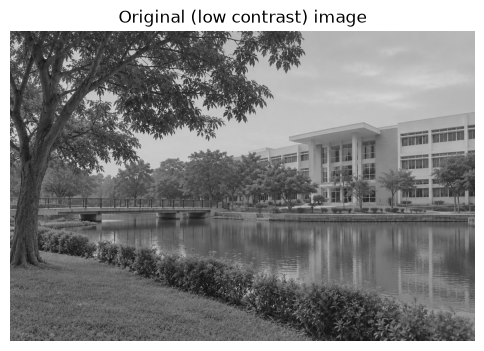

In [3]:
plt.figure(figsize=(6,5))
plt.imshow(img, cmap="gray")
plt.title("Original (low contrast) image")
plt.axis('off')
plt.show()

In [4]:
# Draw manually using numpy
histogram, bin_edges = np.histogram(img.flatten(), bins=256, range=(0,256))

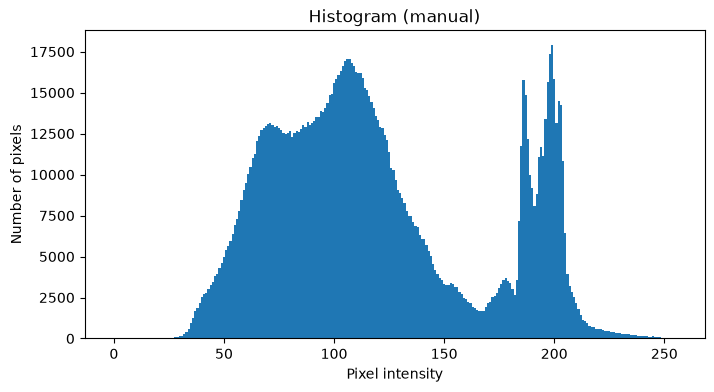

In [5]:
plt.figure(figsize=(8,4))
plt.bar(range(256), histogram, width=1)
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Histogram (manual)")
plt.show()

x-axis: pixel intensity  from black(0) to white(255)  
y-axis: number of pixels at each intensity  
tall peaks: many pixels have those intensity values  
values concentrated on the left: image is generally dark  
values concentrated on the right: image is generally bright

In [6]:
print(f"Most common intensity value: {np.argmax(histogram)}")
print(f"Number of pixels at that intensity: {histogram.max()}")

Most common intensity value: 199
Number of pixels at that intensity: 17897


In [7]:
# Histogram using OpenCV
histogram_cv2 = cv2.calcHist([img], [0], None, [256], [0,256])

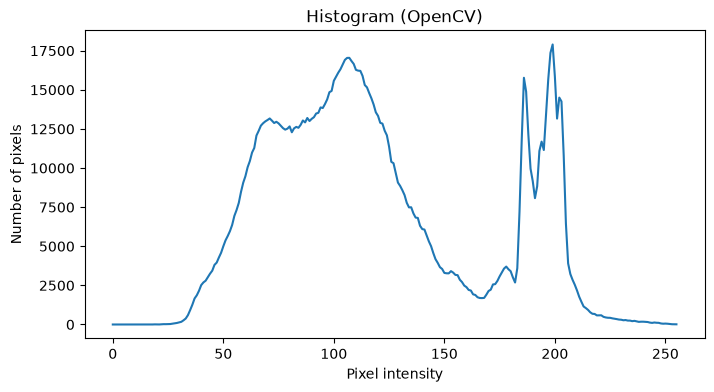

In [8]:
plt.figure(figsize=(8,4))
plt.plot(histogram_cv2.flatten())
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Histogram (OpenCV)")
plt.show()

In [9]:
# Build CDF and remap pixels (same formula OpenCV uses, ignoring empty bins)
cdf = histogram.cumsum()
cdf_min = cdf[cdf > 0].min()
cdf_normalized = np.round((cdf - cdf_min) * 255 / (cdf[-1] - cdf_min))
cdf_normalized = np.clip(cdf_normalized, 0, 255)

In [10]:
equalized_manual = np.interp(img.flatten(), np.arange(256), cdf_normalized)
equalized_manual = equalized_manual.reshape(img.shape).astype(np.uint8)

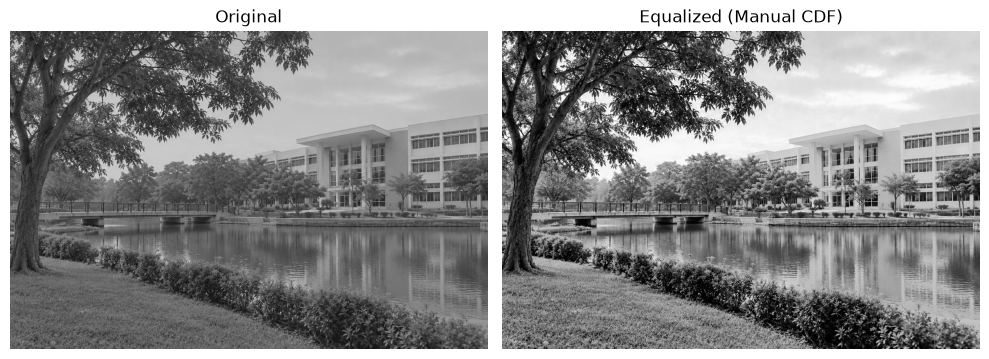

In [11]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(equalized_manual, cmap='gray')
plt.title("Equalized (Manual CDF)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [12]:
# Equalization directly using OpenCV
eq_cv2 = cv2.equalizeHist(img)

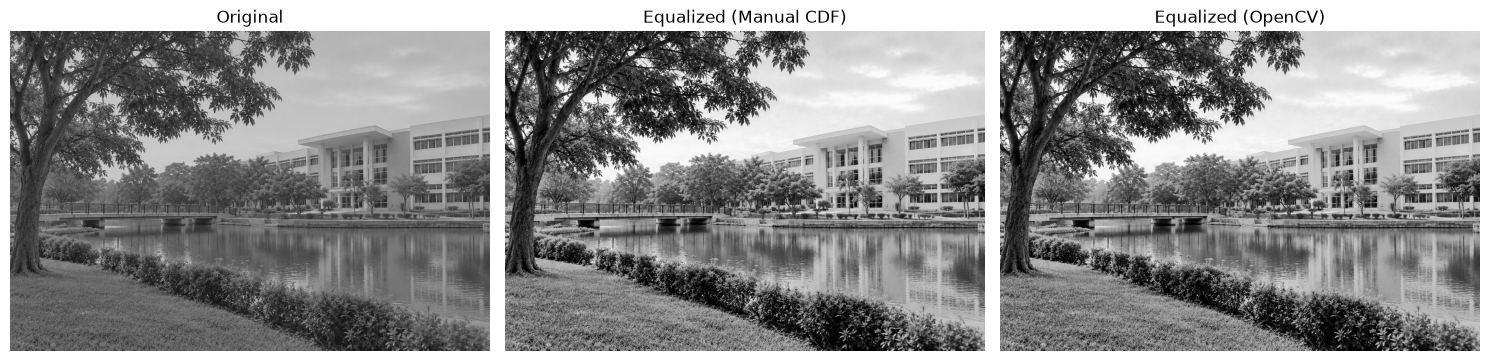

In [13]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(equalized_manual, cmap='gray')
plt.title("Equalized (Manual CDF)")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(eq_cv2, cmap='gray')
plt.title("Equalized (OpenCV)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
# Compare Histograms side by side (np.histogram returns (counts, edges); keep counts only)
hist_manual_eq, _ = np.histogram(equalized_manual.flatten(), bins=256, range=(0,256))
hist_cv2_eq, _ = np.histogram(eq_cv2.flatten(), bins=256, range=(0,256))

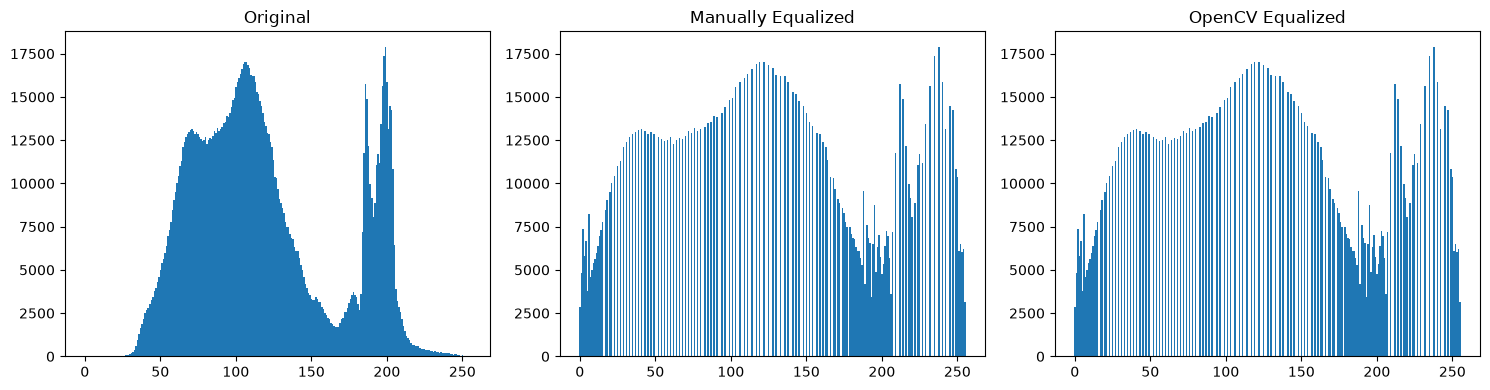

In [15]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.bar(range(256), histogram, width=1)
plt.title("Original")

plt.subplot(1,3,2)
plt.bar(range(256), hist_manual_eq, width=1)
plt.title("Manually Equalized")

plt.subplot(1,3,3)
plt.bar(range(256), hist_cv2_eq, width=1)
plt.title("OpenCV Equalized")

plt.tight_layout()
plt.show()